In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

In [2]:
data = fetch_california_housing(as_frame=True)

X = data.data
y = data.target

### Train/Validation/Test Split:
Splitting into three sets ensures your validation set guides early stopping without leaking information into your final test evaluation.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train shape: {X_train.shape} | Val shape: {X_val.shape} | Test shape: {X_test.shape}")

Train shape: (13209, 8) | Val shape: (3303, 8) | Test shape: (4128, 8)


### Categorical Feature Handling (Optional):
If dataset includes categorical columns, then convert them to pandas category dtype so XGBoost can handle them natively without one-hot encoding.

In [4]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

for col in cat_cols:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")
    X_test[col] = X_test[col].astype("category")

### Train Baseline Model with Early Stopping:
Using a high `n_estimators` paired with `early_stopping_rounds` lets XGBoost automatically find the optimal number of trees.

In [5]:
model = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    enable_categorical=True,
    early_stopping_rounds=50,
    eval_metric="rmse",
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")
print(f"Best validation RMSE: {model.best_score:.4f}")

Best iteration: 1066
Best validation RMSE: 0.4637


### Evaluate on Test Set:

In [6]:
y_pred = model.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE:  {mae:.4f}")
print(f"Test R²:   {r2:.4f}")

Test RMSE: 0.4370
Test MAE:  0.2847
Test R²:   0.8543


### Diagnostics — Learning Curve & Feature Importance:

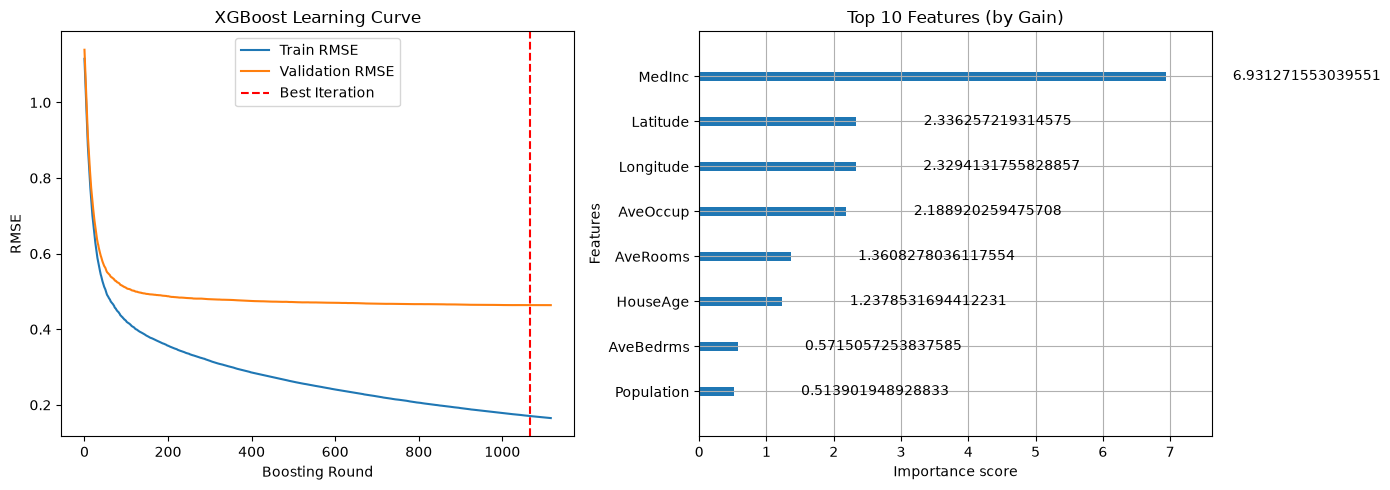

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results = model.evals_result()
axes[0].plot(results["validation_0"]["rmse"], label="Train RMSE")
axes[0].plot(results["validation_1"]["rmse"], label="Validation RMSE")
axes[0].axvline(model.best_iteration, color="red", linestyle="--", label="Best Iteration")
axes[0].set_title("XGBoost Learning Curve")
axes[0].set_xlabel("Boosting Round")
axes[0].set_ylabel("RMSE")
axes[0].legend()

xgb.plot_importance(
    model,
    ax=axes[1],
    importance_type="gain",
    max_num_features=10,
    title="Top 10 Features (by Gain)",
)

plt.tight_layout()
plt.show()

### Hyperparameter Tuning with RandomizedSearchCV:

In [8]:
param_dist = {
    "max_depth": [3, 4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1.0, 5.0, 10.0],
}

base_estimator = xgb.XGBRegressor(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    enable_categorical=True,
)

search = RandomizedSearchCV(
    estimator=base_estimator,
    param_distributions=param_dist,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print(f"Best CV RMSE: {-search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 1.0, 'min_child_weight': 10, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV RMSE: 0.4524
